# FactoredMLE — Joint Angle + Distance Decoding

**Model:** `template(c, a, d) = mu_angle(c, a) × gain(c, d)`
- `mu_angle(c, a)` — RF profile: mean response of cell *c* at position *a*, averaged across distances
- `gain(c, d)` — distance gain: how distance *d* scales cell *c*’s response at its RF peak (mean-normalised)

Distance-invariant cells have flat gain ≈ [1,1,1,1] and drop out of distance decoding naturally.
Primary metric: **Distance MAE** (continuous softmax readout). Secondary: hard-argmax accuracy.

**Structure:**
- **Part 1** — Multi-session, condition-averaged (binocular vs monocular; DTI subset analysis)
- **Part 2** — Single-session, single-trial (realistic lower bound on performance)

In [4]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
from path_setup import setup_project_path
setup_project_path()

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp, softmax
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.decoding.SessionAggregator import SessionAggregator
from src.decoding.Decoders import (
    FactoredMLE,
)

%load_ext autoreload
%autoreload 2

In [5]:
MOUSE                 = 'SAM041'
EXPERIMENT            = 'tiling_120um'
RELIABILITY_THRESHOLD = 0.85
N_REPEATS             = 10
N_FOLDS               = 5
RANDOM_STATE          = 42
np.random.seed(RANDOM_STATE)

---
## Part 1 — Multi-session, condition-averaged FactoredMLE

Each test observation is the *mean* response over a random half of trials → high SNR.  
This is the inflated-but-clean baseline.

### § 1.0 — Data loading

[ok] Loaded aggregated traces from cache
n_neurons=2990,  n_positions=59,  n_distances=4


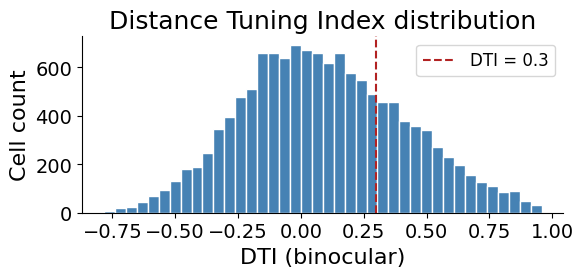

DTI > 0.3: 3396 / 2990 cells (26.2%)


In [14]:
agg = SessionAggregator(
    mouse_name=MOUSE,
    experiment_name=EXPERIMENT,
    reliability_threshold=RELIABILITY_THRESHOLD,
    force_recompute = False
)

# Full condition-averaged cube (for gain visualisation and DTI inspection)
X_cond, distances = agg.get_decoder_data_by_condition(monocular=0)

n_neurons, n_positions, n_distances = X_cond.shape
print(f'n_neurons={n_neurons},  n_positions={n_positions},  n_distances={n_distances}')

# Cell metadata
bino_dti  = agg.df['binocular'].apply(lambda d: d['DTI']).values           # (n_neurons,)
bino_corr = agg.df['binocular'].apply(lambda d: d['reliable_corr']).values  # (n_neurons,)
rank_dti_desc = np.argsort(bino_dti)[::-1]   # highest DTI first

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(bino_dti, bins=40, color='steelblue', edgecolor='white')
ax.axvline(0.3, color='firebrick', linestyle='--', label='DTI = 0.3')
ax.set(xlabel='DTI (binocular)', ylabel='Cell count', title='Distance Tuning Index distribution')
ax.legend()
plt.tight_layout(); plt.show()
print(f'DTI > 0.3: {(bino_dti > 0.3).sum()} / {n_neurons} cells ({(bino_dti > 0.3).mean()*100:.1f}%)')

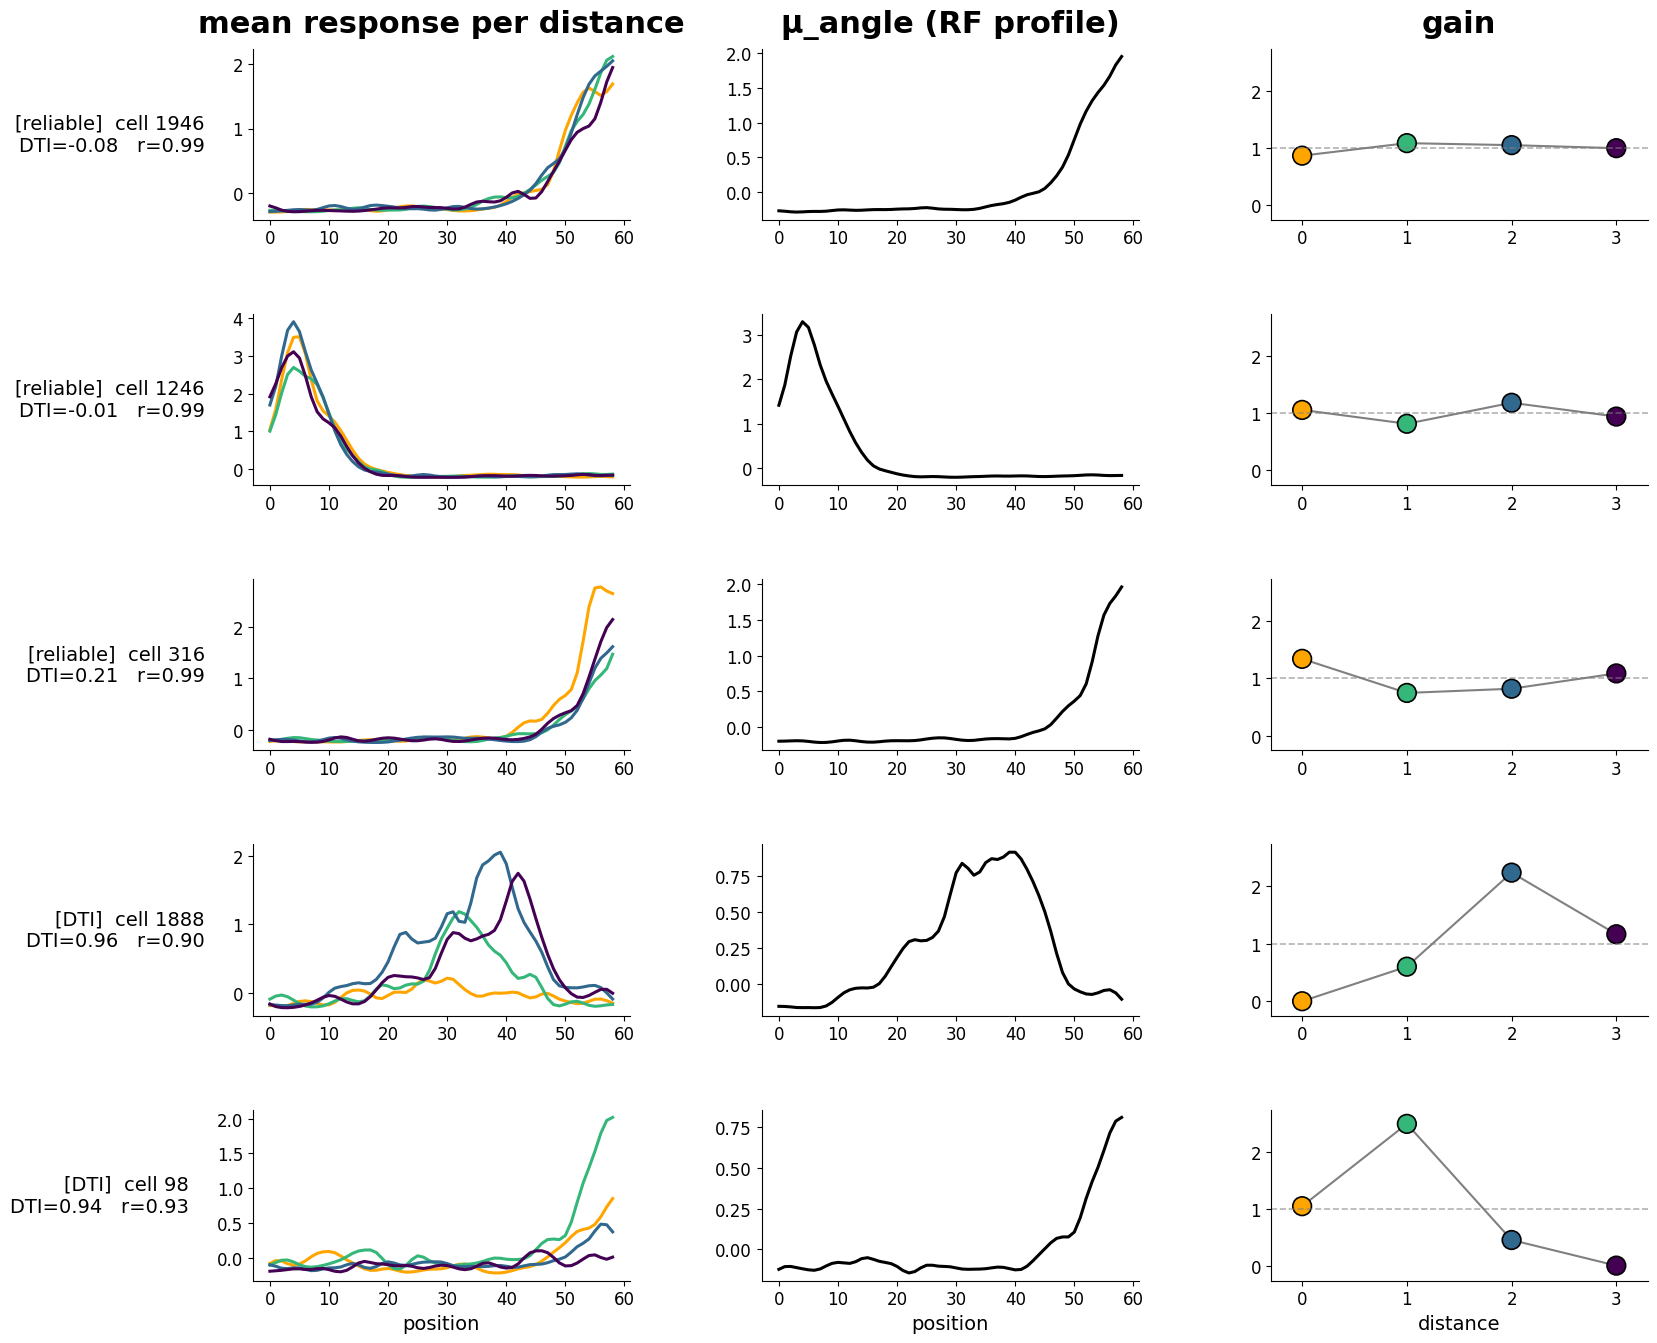

In [29]:
import numpy as np
import matplotlib.pyplot as plt

DISTANCE_COLORS = ['orange', '#35b779', '#31688e', '#440154']
MONOCULAR = 0

# Replicate aggregator's cell selection
cell_indices = agg._get_cell_indices(area=None)
valid_df_idx = []
for idx in cell_indices:
    session_name = agg._df.loc[idx, 'session_name']
    mask = agg._get_trial_mask(session_name, None, MONOCULAR, include_control=False)
    if mask.sum() > 0:
        valid_df_idx.append(idx)
valid_df_idx = np.array(valid_df_idx)
assert len(valid_df_idx) == dec_full.mu_angle.shape[0]

bino_dti_sub  = np.array([agg.df.loc[i, 'binocular']['DTI'] for i in valid_df_idx])
bino_corr_sub = np.array([agg.df.loc[i, 'binocular']['reliable_corr'] for i in valid_df_idx])

top_reliable = np.argsort(bino_corr_sub)[::-1][:3]
dti_rank     = np.argsort(bino_dti_sub)[::-1]
top_dti      = [i for i in dti_rank if i not in top_reliable][:2]
top_idx      = list(top_reliable) + list(top_dti)
labels       = ['reliable']*3 + ['DTI']*2

n_neurons, n_pos, n_dist = X_cond.shape
positions = np.arange(n_pos)
distances_idx = np.arange(n_dist)

g_all = dec_full.gain[top_idx]
g_pad = max(0.1, 0.1 * (g_all.max() - g_all.min()))
g_ylim = (g_all.min() - g_pad, g_all.max() + g_pad)

N_SHOW = len(top_idx)
fig, axes = plt.subplots(N_SHOW, 3, figsize=(18, N_SHOW * 3.2),
                         gridspec_kw={'hspace': 0.55, 'wspace': 0.35})

TITLE_FS = 22
LABEL_FS = 14
TICK_FS  = 12
LEGEND_FS = 13

for row, (cidx, lbl) in enumerate(zip(top_idx, labels)):
    # col 0: mean response per distance
    ax = axes[row, 0]
    for d in range(n_dist):
        ax.plot(positions, X_cond[cidx, :, d],
                color=DISTANCE_COLORS[d], linewidth=2.2,
                label=f'distance {d}' if row == 0 else None)
    ax.set_ylabel(
        f'[{lbl}]  cell {cidx}\nDTI={bino_dti_sub[cidx]:.2f}   '
        f'r={bino_corr_sub[cidx]:.2f}',
        fontsize=LABEL_FS, rotation=0, ha='right', va='center', labelpad=20)
    ax.tick_params(labelsize=TICK_FS)
    if row == 0:
        ax.set_title('mean response per distance',
                     fontsize=TITLE_FS, fontweight='bold', pad=12)
    if row == N_SHOW - 1:
        ax.set_xlabel('position', fontsize=LABEL_FS)

    # col 1: mu_angle
    ax = axes[row, 1]
    ax.plot(positions, dec_full.mu_angle[cidx], 'k-', linewidth=2.2)
    ax.tick_params(labelsize=TICK_FS)
    if row == 0:
        ax.set_title('μ_angle (RF profile)',
                     fontsize=TITLE_FS, fontweight='bold', pad=12)
    if row == N_SHOW - 1:
        ax.set_xlabel('position', fontsize=LABEL_FS)

    # col 2: gain
    ax = axes[row, 2]
    g = dec_full.gain[cidx]
    ax.plot(distances_idx, g, '-', color='gray', linewidth=1.5, zorder=1)
    ax.scatter(distances_idx, g, c=DISTANCE_COLORS, s=180, zorder=2,
               edgecolors='black', linewidths=1.2)
    ax.axhline(1.0, color='gray', linestyle='--', alpha=0.6, linewidth=1.2)
    ax.set_xticks(distances_idx)
    ax.set_xlim(-0.3, n_dist - 0.7)
    ax.set_ylim(g_ylim)
    ax.tick_params(labelsize=TICK_FS)
    if row == 0:
        ax.set_title('gain',
                     fontsize=TITLE_FS, fontweight='bold', pad=12)
    if row == N_SHOW - 1:
        ax.set_xlabel('distance', fontsize=LABEL_FS)

for ax in axes.flat:
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.show()


In [ ]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.data.WidefieldAligner import WidefieldAligner
from src.data.WidefieldTransformer import WidefieldMapper
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SingleSessionVisualizer, MultiSessionVisualizer
from src.viz.WidefieldVisualizer import WidefieldVisualizer
from src.workflows import load_dataframe

import numpy as np
import matplotlib.pyplot as plt
import pickle
import pandas as pd

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM040'
experiment_name = 'tiling_120um'

combined_df = load_dataframe(mouse_name=mouse_name, experiment_name=experiment_name)
session_df = (
    combined_df[combined_df['session_name'] == '260428_SAM045_tiling_8_120um']
    .drop(columns='session_name')
    .reset_index(drop=True)
)

multi_session_dir = r'D:/data-distance-coding-project/multi-session-data/'
multi_session_dir = os.path.join(multi_session_dir, f'SAM045_{experiment_name}')
alignment_name = f'SAM045_tiling_120um_alignment_parameters.pkl'
alignment_path = os.path.join(multi_session_dir, alignment_name)

with open(alignment_path, 'rb') as f:
    alignment_params = pickle.load(f)
    print(f"Alignment parameters loaded from {alignment_name}")

from src.data.WidefieldTransformer import WidefieldMapper
mapper = WidefieldMapper(alignment_params)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[ok] Loaded DataFrame from D:/data-distance-coding-project/multi-session-data\SAM040_tiling_120um\SAM040_tiling_120um_combined_sessions.pkl (14173 cells)
Alignment parameters loaded from SAM045_tiling_120um_alignment_parameters.pkl


### § 1.2 — Binocular baseline (cross-validated)

**Primary metric**: Distance MAE (continuous softmax) and Angle MAE (°).  
**Secondary**: Distance accuracy % (hard argmax, chance = 25%).

In [66]:
from scipy.stats import ttest_ind

def _sig_label(p):
    if p > 0.05:  return 'ns'
    if p > 0.01:  return '*'
    if p > 0.001: return '**'
    return '***'

def plot_angle_decoding(res, title='',
                        angle_ranges=((-30, -15), (-15, 15), (15, 60)),
                        range_labels=('Left eye', 'Both eyes', 'Right eye')):
    range_colors = ['firebrick', 'mediumpurple', 'steelblue']
    angle_axis = res['angle_axis']

    errors = np.abs(res['a_pred'] - res['a_true'][np.newaxis])
    n_repeats, n_distances, n_positions = errors.shape

    a_true_flat = np.tile(res['a_true'][np.newaxis], (n_repeats, 1, 1)).ravel()
    a_pred_flat = res['a_pred'].ravel()

    mae_by_pos = errors.mean(axis=(0, 1))
    sem_by_pos = errors.reshape(-1, n_positions).std(axis=0) / np.sqrt(n_repeats * n_distances)
    overall_mae = errors.mean()

    fig, axes = plt.subplots(1, 3, figsize=(16, 5),
                             gridspec_kw={'width_ratios': [1, 1.5, 1]})

    # Panel 1: error density matrix
    ax = axes[0]
    bins = np.linspace(angle_axis[0], angle_axis[-1], 20)
    h, xedges, yedges = np.histogram2d(a_true_flat, a_pred_flat, bins=bins)
    ax.pcolormesh(xedges, yedges, h.T, cmap='Blues')
    ax.plot([angle_axis[0], angle_axis[-1]], [angle_axis[0], angle_axis[-1]],
            'r--', linewidth=1.2)
    ax.set(xlabel='True angle (°)', ylabel='Predicted angle (°)',
           title=f'MAE = {overall_mae:.2f}°', aspect='equal')

    # Panel 2: MAE by position
    ax = axes[1]
    for (lo, hi), color in zip(angle_ranges, range_colors):
        ax.axvspan(lo, hi, color=color, alpha=0.12, zorder=0)
    ax.plot(angle_axis, mae_by_pos, color='k', linewidth=1.8)
    ax.fill_between(angle_axis,
                    mae_by_pos - sem_by_pos,
                    mae_by_pos + sem_by_pos,
                    color='k', alpha=0.2)
    ax.set(xlabel='Angle (°)', ylabel='MAE (°)', title='Angle error by position')

    # Panel 3: boxplot by range + significance bars
    ax = axes[2]
    box_data, box_labels = [], []
    for (lo, hi), label in zip(angle_ranges, range_labels):
        mask = (angle_axis >= lo) & (angle_axis < hi)
        box_data.append(mae_by_pos[mask])
        box_labels.append(label)
    bp = ax.boxplot(box_data, labels=box_labels, patch_artist=True,
                    medianprops=dict(color='white', linewidth=2))
    for patch, color in zip(bp['boxes'], range_colors):
        patch.set(facecolor=color, alpha=0.7)
    ax.axhline(overall_mae, color='gray', linestyle='--', linewidth=1,
               label=f'Overall ({overall_mae:.2f}°)')
    ax.set(ylabel='Angle error (°)', title='Error by eye region')
    ax.tick_params(axis='x', rotation=15)
    ax.legend(fontsize=9)

    # Significance bars
    y_max = max(d.max() for d in box_data)
    y_step = y_max * 0.15
    for k, (i, j) in enumerate([(0, 1), (0, 2), (1, 2)]):
        _, p = ttest_ind(box_data[i], box_data[j])
        y = y_max + y_step * (k + 1)
        x1, x2 = i + 1, j + 1
        ax.plot([x1, x1, x2, x2], [y - y_step * 0.2, y, y, y - y_step * 0.2],
                color='k', linewidth=1.2)
        ax.text((x1 + x2) / 2, y + y_step * 0.05, _sig_label(p),
                ha='center', va='bottom', fontsize=11)
    ax.set_ylim(top=y_max + y_step * 4.5)

    if title:
        fig.suptitle(title, fontsize=20)
    plt.tight_layout()
    return fig

def plot_angle_decoding_comparison(results, labels,
                                   angle_ranges=((-30, -15), (-15, 15), (15, 45)),
                                   range_labels=('Left eye', 'Both eyes', 'Right eye'),
                                   colors=None, title=''):
    if colors is None:
        colors = ['steelblue', 'firebrick', 'seagreen', 'darkorange', 'mediumpurple']
    
    n_conds  = len(results)
    n_ranges = len(angle_ranges)
    angle_axis = results[0]['angle_axis']

    # Pre-compute per-condition mae_by_pos and sem_by_pos
    mae_by_pos_all, sem_by_pos_all, box_data_all = [], [], []
    for res in results:
        errors = np.abs(res['a_pred'] - res['a_true'][np.newaxis])
        n_repeats, n_distances, n_positions = errors.shape
        mae = errors.mean(axis=(0, 1))
        sem = errors.reshape(-1, n_positions).std(axis=0) / np.sqrt(n_repeats * n_distances)
        mae_by_pos_all.append(mae)
        sem_by_pos_all.append(sem)
        box_data_all.append([
            mae[(angle_axis >= lo) & (angle_axis < hi)]
            for lo, hi in angle_ranges
        ])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                             gridspec_kw={'width_ratios': [2, 1.2]})
    range_bg_colors = ['firebrick', 'mediumpurple', 'steelblue']

    # Panel 1: MAE by angle position
    ax = axes[0]
    for (lo, hi), bg in zip(angle_ranges, range_bg_colors):
        ax.axvspan(lo, hi, color=bg, alpha=0.08, zorder=0)
    for mae, sem, label, color in zip(mae_by_pos_all, sem_by_pos_all, labels, colors):
        ax.plot(angle_axis, mae, color=color, linewidth=1.8, label=label)
        ax.fill_between(angle_axis, mae - sem, mae + sem, color=color, alpha=0.2)
    ax.set(xlabel='Angle (°)', ylabel='MAE (°)', title='Angle error by position')
    ax.legend()

    # Panel 2: grouped boxplot + significance bars
    ax = axes[1]
    width  = 0.6 / n_conds
    step   = width * 1.1
    starts = np.arange(-(n_conds - 1), n_conds, 2) * step / 2  # symmetric offsets

    for ci, (box_data, label, color) in enumerate(zip(box_data_all, labels, colors)):
        positions = [g + 1 + starts[ci] for g in range(n_ranges)]
        bp = ax.boxplot(box_data, positions=positions, widths=width * 0.9,
                        patch_artist=True,
                        medianprops=dict(color='white', linewidth=2),
                        whiskerprops=dict(color=color),
                        capprops=dict(color=color),
                        flierprops=dict(marker='o', markersize=3, color=color, alpha=0.5))
        for patch in bp['boxes']:
            patch.set(facecolor=color, alpha=0.7)

    # Significance bars within each range group (all condition pairs)
    pairs = [(i, j) for i in range(n_conds) for j in range(i + 1, n_conds)]
    for g in range(n_ranges):
        group_data = [box_data_all[ci][g] for ci in range(n_conds)]
        y_max  = max(d.max() for d in group_data)
        y_step = y_max * 0.18
        for k, (i, j) in enumerate(pairs):
            _, p = ttest_ind(group_data[i], group_data[j])
            x1 = g + 1 + starts[i]
            x2 = g + 1 + starts[j]
            y  = y_max + y_step * (k + 1)
            ax.plot([x1, x1, x2, x2], [y - y_step * 0.2, y, y, y - y_step * 0.2],
                    color='k', linewidth=1.2)
            ax.text((x1 + x2) / 2, y + y_step * 0.05, _sig_label(p),
                    ha='center', va='bottom', fontsize=10)

    ax.set_xticks(np.arange(1, n_ranges + 1))
    ax.set_xticklabels(range_labels, rotation=15)
    ax.set(ylabel='MAE (°)', title='Error by eye region')

    # Legend from dummy patches
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor=colors[ci], label=labels[ci]) for ci in range(n_conds)],
              fontsize=9)

    if title:
        fig.suptitle(title, fontsize=20)
    plt.tight_layout()
    return fig


In [68]:
agg = SessionAggregator(
    mouse_name='SAM041',
    experiment_name=EXPERIMENT,
    reliable_only = False
)

Cache parameters don't match, recomputing...
[...] Building traces for SAM041_tiling_120um
[ok] Loaded DataFrame from D:\data-distance-coding-project\multi-session-data\SAM041_tiling_120um\SAM041_tiling_120um_combined_sessions.pkl (12948 cells)
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Normalizing traces to 59 positions
Loading traces for 251126_SAM041_tiling_1_120um (1299 cells)...
Directory results already exists
Loading traces for 251126_SAM041_tiling_2_120um (2130 cells)...
Directory results already exists
Loading traces for 251126_SAM041_tiling_5_120um (2426 cells)...
Directory results already exists
Loading traces for 251126_SAM041_tiling_6_120um (1084 cells)...
Directory results already exists
Loading traces for 251126_SAM041_ti

In [71]:
agg = SessionAggregator(
    mouse_name='SAM043',
    experiment_name=EXPERIMENT,
    force_recompute = True
)

[...] Building traces for SAM043_tiling_120um
[ok] Loaded DataFrame from D:\data-distance-coding-project\multi-session-data\SAM043_tiling_120um\SAM043_tiling_120um_combined_sessions.pkl (8365 cells)
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Directory results already exists
Normalizing traces to 61 positions
Loading traces for 251213_SAM043_tiling_5_120um (1161 cells)...
Directory results already exists
Loading traces for 251215_SAM043_tiling_2_120um (1216 cells)...
Directory results already exists
Loading traces for 251215_SAM043_tiling_8_120um (1577 cells)...
Directory results already exists
Loading traces for 251216_SAM043_tiling_1_120um (762 cells)...
Directory results already exists
Loading traces for 251216_SAM043_tiling_6_120um (1722 cells)...
Directory results already exists
Loading traces for 251217_SAM043_tiling_4_120um (55

[ok] Loaded aggregated traces from cache


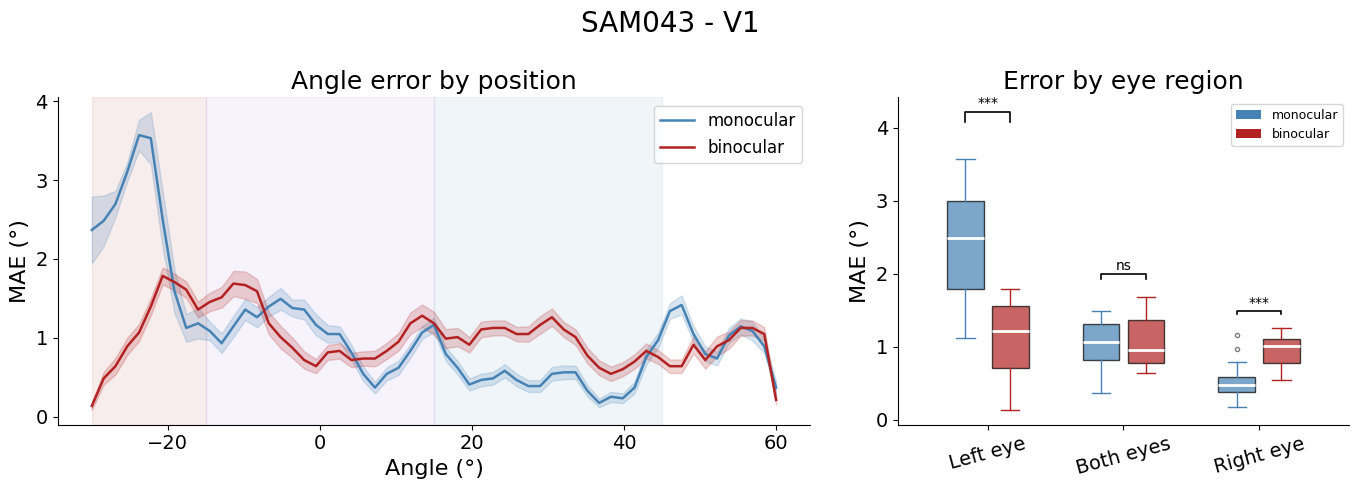

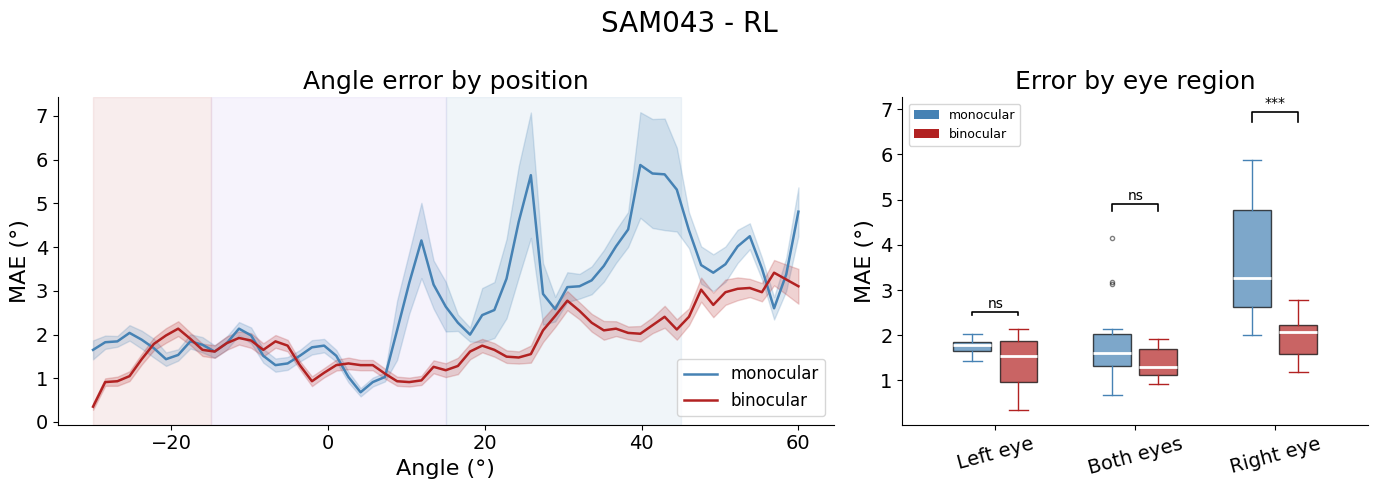

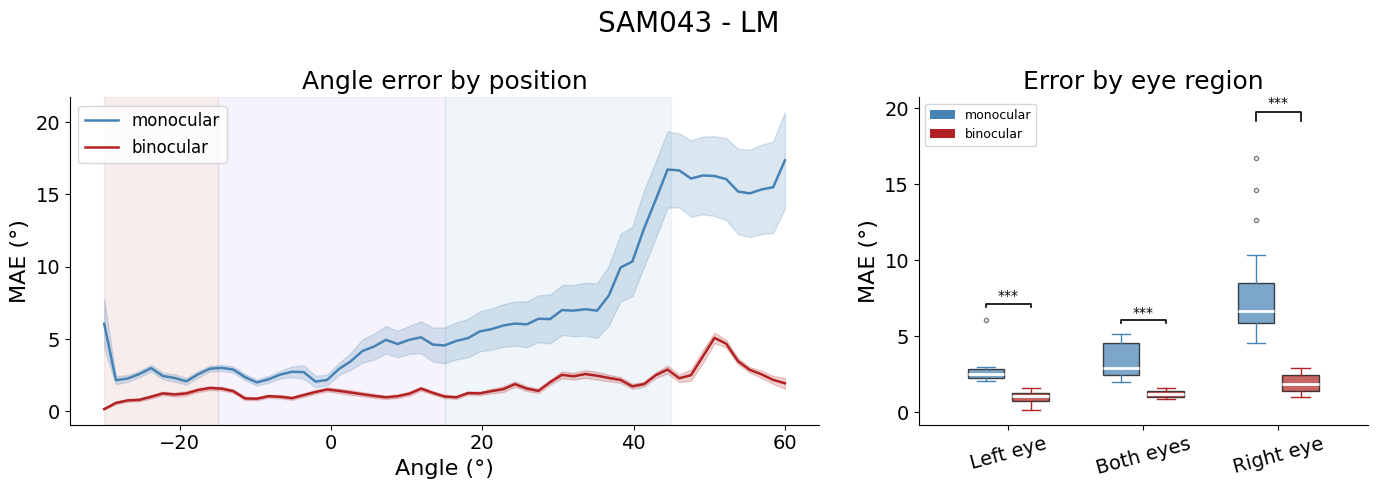

In [ ]:
agg = SessionAggregator(
    mouse_name='SAM041',
    experiment_name=EXPERIMENT,
    reliable_only = False
)

bino_results_V1 = cross_validate_averaged(agg, monocular = 0, area = 'V1', n_repeats = 20)
mono_results_V1 = cross_validate_averaged(agg, monocular = 1, area = 'V1', n_repeats = 20)

bino_results_LM = cross_validate_averaged(agg, monocular = 0, area = 'LM', n_repeats = 20)
mono_results_LM = cross_validate_averaged(agg, monocular = 1, area = 'LM', n_repeats = 20)

bino_results_RL = cross_validate_averaged(agg, monocular = 0, area = 'RL', n_repeats = 20)
mono_results_RL = cross_validate_averaged(agg, monocular = 1, area = 'RL', n_repeats = 20)

fig = plot_angle_decoding_comparison([mono_results_V1, bino_results_V1], labels=['monocular', 'binocular'], title='SAM043 - V1')
fig = plot_angle_decoding_comparison([mono_results_RL, bino_results_RL], labels=['monocular', 'binocular'], title='SAM043 - RL')
fig = plot_angle_decoding_comparison([mono_results_LM, bino_results_LM], labels=['monocular', 'binocular'], title='SAM043 - LM')

In [44]:
from scipy.stats import ttest_ind

def _sig_label(p):
    if p > 0.05:  return 'ns'
    if p > 0.01:  return '*'
    if p > 0.001: return '**'
    return '***'

def plot_angle_decoding(res, title='',
                        angle_ranges=((-30, -15), (-15, 15), (15, 60)),
                        range_labels=('Left eye', 'Both eyes', 'Right eye')):
    range_colors = ['firebrick', 'mediumpurple', 'steelblue']
    angle_axis = res['angle_axis']

    errors = np.abs(res['a_pred'] - res['a_true'][np.newaxis])
    n_repeats, n_distances, n_positions = errors.shape

    a_true_flat = np.tile(res['a_true'][np.newaxis], (n_repeats, 1, 1)).ravel()
    a_pred_flat = res['a_pred'].ravel()

    mae_by_pos = errors.mean(axis=(0, 1))
    sem_by_pos = errors.reshape(-1, n_positions).std(axis=0) / np.sqrt(n_repeats * n_distances)
    overall_mae = errors.mean()

    fig, axes = plt.subplots(1, 3, figsize=(16, 5),
                             gridspec_kw={'width_ratios': [1, 1.5, 1]})

    # Panel 1: error density matrix
    ax = axes[0]
    bins = np.linspace(angle_axis[0], angle_axis[-1], 20)
    h, xedges, yedges = np.histogram2d(a_true_flat, a_pred_flat, bins=bins)
    ax.pcolormesh(xedges, yedges, h.T, cmap='Blues')
    ax.plot([angle_axis[0], angle_axis[-1]], [angle_axis[0], angle_axis[-1]],
            'r--', linewidth=1.2)
    ax.set(xlabel='True angle (°)', ylabel='Predicted angle (°)',
           title=f'MAE = {overall_mae:.2f}°', aspect='equal')

    # Panel 2: MAE by position
    ax = axes[1]
    for (lo, hi), color in zip(angle_ranges, range_colors):
        ax.axvspan(lo, hi, color=color, alpha=0.12, zorder=0)
    ax.plot(angle_axis, mae_by_pos, color='k', linewidth=1.8)
    ax.fill_between(angle_axis,
                    mae_by_pos - sem_by_pos,
                    mae_by_pos + sem_by_pos,
                    color='k', alpha=0.2)
    ax.set(xlabel='Angle (°)', ylabel='MAE (°)', title='Angle error by position')

    # Panel 3: boxplot by range + significance bars
    ax = axes[2]
    box_data, box_labels = [], []
    for (lo, hi), label in zip(angle_ranges, range_labels):
        mask = (angle_axis >= lo) & (angle_axis < hi)
        box_data.append(mae_by_pos[mask])
        box_labels.append(label)
    bp = ax.boxplot(box_data, labels=box_labels, patch_artist=True,
                    medianprops=dict(color='white', linewidth=2))
    for patch, color in zip(bp['boxes'], range_colors):
        patch.set(facecolor=color, alpha=0.7)
    ax.axhline(overall_mae, color='gray', linestyle='--', linewidth=1,
               label=f'Overall ({overall_mae:.2f}°)')
    ax.set(ylabel='Angle error (°)', title='Error by eye region')
    ax.tick_params(axis='x', rotation=15)
    ax.legend(fontsize=9)

    # Significance bars
    y_max = max(d.max() for d in box_data)
    y_step = y_max * 0.15
    for k, (i, j) in enumerate([(0, 1), (0, 2), (1, 2)]):
        _, p = ttest_ind(box_data[i], box_data[j])
        y = y_max + y_step * (k + 1)
        x1, x2 = i + 1, j + 1
        ax.plot([x1, x1, x2, x2], [y - y_step * 0.2, y, y, y - y_step * 0.2],
                color='k', linewidth=1.2)
        ax.text((x1 + x2) / 2, y + y_step * 0.05, _sig_label(p),
                ha='center', va='bottom', fontsize=11)
    ax.set_ylim(top=y_max + y_step * 4.5)

    if title:
        fig.suptitle(title, fontsize=20)
    plt.tight_layout()
    return fig

def plot_angle_decoding_comparison(results, labels,
                                   angle_ranges=((-30, -15), (-15, 15), (15, 60)),
                                   range_labels=('Left eye', 'Both eyes', 'Right eye'),
                                   colors=None, title=''):
    if colors is None:
        colors = ['steelblue', 'firebrick', 'seagreen', 'darkorange', 'mediumpurple']
    
    n_conds  = len(results)
    n_ranges = len(angle_ranges)
    angle_axis = results[0]['angle_axis']

    # Pre-compute per-condition mae_by_pos and sem_by_pos
    mae_by_pos_all, sem_by_pos_all, box_data_all = [], [], []
    for res in results:
        errors = np.abs(res['a_pred'] - res['a_true'][np.newaxis])
        n_repeats, n_distances, n_positions = errors.shape
        mae = errors.mean(axis=(0, 1))
        sem = errors.reshape(-1, n_positions).std(axis=0) / np.sqrt(n_repeats * n_distances)
        mae_by_pos_all.append(mae)
        sem_by_pos_all.append(sem)
        box_data_all.append([
            mae[(angle_axis >= lo) & (angle_axis < hi)]
            for lo, hi in angle_ranges
        ])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                             gridspec_kw={'width_ratios': [2, 1.2]})
    range_bg_colors = ['firebrick', 'mediumpurple', 'steelblue']

    # Panel 1: MAE by angle position
    ax = axes[0]
    for (lo, hi), bg in zip(angle_ranges, range_bg_colors):
        ax.axvspan(lo, hi, color=bg, alpha=0.08, zorder=0)
    for mae, sem, label, color in zip(mae_by_pos_all, sem_by_pos_all, labels, colors):
        ax.plot(angle_axis, mae, color=color, linewidth=1.8, label=label)
        ax.fill_between(angle_axis, mae - sem, mae + sem, color=color, alpha=0.2)
    ax.set(xlabel='Angle (°)', ylabel='MAE (°)', title='Angle error by position')
    ax.legend()

    # Panel 2: grouped boxplot + significance bars
    ax = axes[1]
    width  = 0.6 / n_conds
    step   = width * 1.1
    starts = np.arange(-(n_conds - 1), n_conds, 2) * step / 2  # symmetric offsets

    for ci, (box_data, label, color) in enumerate(zip(box_data_all, labels, colors)):
        positions = [g + 1 + starts[ci] for g in range(n_ranges)]
        bp = ax.boxplot(box_data, positions=positions, widths=width * 0.9,
                        patch_artist=True,
                        medianprops=dict(color='white', linewidth=2),
                        whiskerprops=dict(color=color),
                        capprops=dict(color=color),
                        flierprops=dict(marker='o', markersize=3, color=color, alpha=0.5))
        for patch in bp['boxes']:
            patch.set(facecolor=color, alpha=0.7)

    # Significance bars within each range group (all condition pairs)
    pairs = [(i, j) for i in range(n_conds) for j in range(i + 1, n_conds)]
    for g in range(n_ranges):
        group_data = [box_data_all[ci][g] for ci in range(n_conds)]
        y_max  = max(d.max() for d in group_data)
        y_step = y_max * 0.18
        for k, (i, j) in enumerate(pairs):
            _, p = ttest_ind(group_data[i], group_data[j])
            x1 = g + 1 + starts[i]
            x2 = g + 1 + starts[j]
            y  = y_max + y_step * (k + 1)
            ax.plot([x1, x1, x2, x2], [y - y_step * 0.2, y, y, y - y_step * 0.2],
                    color='k', linewidth=1.2)
            ax.text((x1 + x2) / 2, y + y_step * 0.05, _sig_label(p),
                    ha='center', va='bottom', fontsize=10)

    ax.set_xticks(np.arange(1, n_ranges + 1))
    ax.set_xticklabels(range_labels, rotation=15)
    ax.set(ylabel='MAE (°)', title='Error by eye region')

    # Legend from dummy patches
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor=colors[ci], label=labels[ci]) for ci in range(n_conds)],
              fontsize=9)

    if title:
        fig.suptitle(title, fontsize=20)
    plt.tight_layout()
    return fig


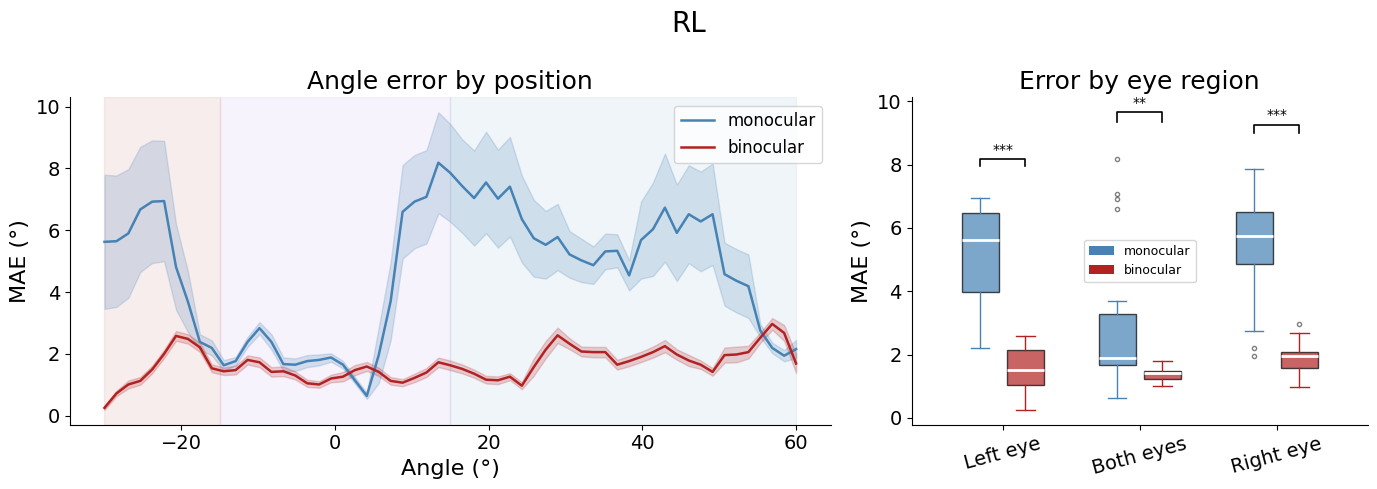

In [53]:
fig = plot_angle_decoding_comparison([mono_results_RL, bino_results_RL], labels=['monocular', 'binocular'], title='RL')

In [ ]:
deg_true = bino_res['a_true'] * deg_per_pos - 20
deg_pred = bino_res['a_pred'] * deg_per_pos - 20
figure = FactoredMLE.plot_distance_results(bino_res, title = 'binocular')
figure = FactoredMLE.plot_distance_results(mono_res, title = 'monocular')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# --- Angle scatter ---
ax = axes[0]
ax.scatter(deg_true, deg_pred, alpha=0.3, s=15, color='steelblue', linewidths=0)
ax.plot([-20, 60], [-20, 60], 'r--', linewidth=1.2)
ax.set(xlabel='True angle (°)', ylabel='Predicted angle (°)',
       title=f'Angle decoding\nMAE = {np.mean(bino_res["angle_maes"]):.2f}°', aspect='equal')

# --- Distance scatter (continuous softmax) ---
ax = axes[1]
jitter = np.random.uniform(-0.08, 0.08, len(bino_res['d_true']))
ax.scatter(distances[bino_res['d_true']] + jitter, bino_res['d_pred_cont'],
           alpha=0.35, s=12, color='darkorange', linewidths=0)
ax.plot([distances[0], distances[-1]], [distances[0], distances[-1]], 'r--', linewidth=1.2)
ax.set(xlabel='True distance', ylabel='Predicted distance (softmax)',
       title=f'Distance decoding (continuous)\nMAE = {np.mean(bino_res["dist_maes_cont"]):.3f}')
ax.set_xticks(distances)

# --- Distance confusion matrix (hard argmax) ---
ax = axes[2]
cm   = confusion_matrix(bino_res['d_true'], bino_res['d_pred_hard'],
                        labels=list(range(n_distances)), normalize='true')
disp = ConfusionMatrixDisplay(cm, display_labels=[f'd={d}' for d in distances])
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Distance confusion (hard argmax)\nacc = {np.mean(bino_res["dist_accs"])*100:.1f}%  (chance 25%)')

plt.suptitle('Binocular — condition-averaged FactoredMLE', fontsize=12)
plt.tight_layout(); plt.show()

In [ ]:
FactoredMLE.plot_distance_results(bino_res, distances, deg_axis,
                                   title='Binocular — condition-averaged')
plt.show()

FactoredMLE.plot_angle_results(bino_res, deg_axis, deg_per_pos,
                                title='Binocular — condition-averaged')
plt.show()

### § 1.3 — Binocular vs Monocular

In [ ]:
mono_res = run_cv_cond_averaged(
    agg, monocular=1, distances=distances,
    n_positions=n_positions, deg_per_pos=deg_per_pos,
)

print(f"{'':20s}  {'Angle MAE (°)':>16s}  {'Dist MAE':>12s}  {'Dist acc (%)':>14s}")
for name, res in [('Binocular', bino_res), ('Monocular', mono_res)]:
    print(f"{name:20s}  "
          f"{np.mean(res['angle_maes']):>7.2f} ± {np.std(res['angle_maes']):.2f}   "
          f"{np.mean(res['dist_maes_cont']):>6.3f} ± {np.std(res['dist_maes_cont']):.3f}  "
          f"{np.mean(res['dist_accs'])*100:>7.1f} ± {np.std(res['dist_accs'])*100:.1f}")

ValueError: x and y must be the same size

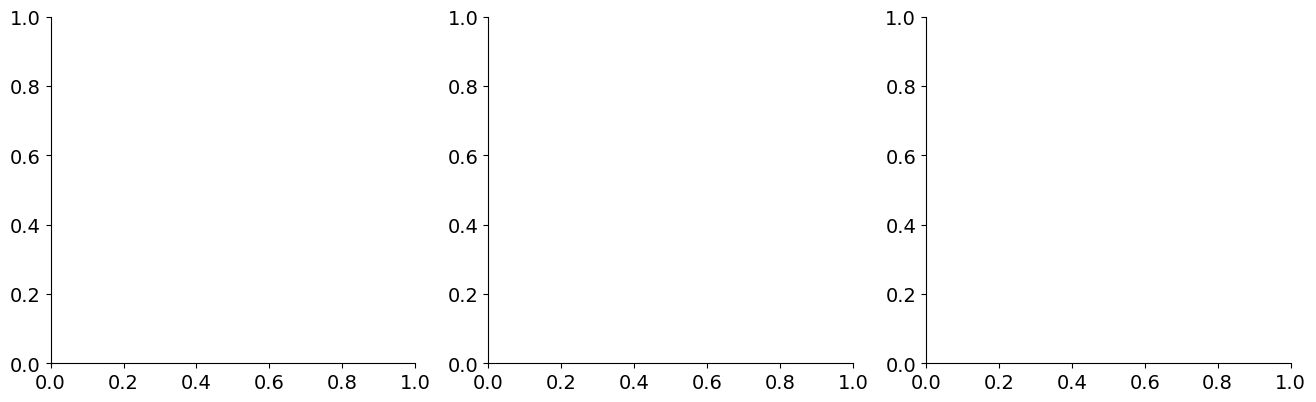

In [137]:
cond_map = {'Binocular': (bino_res, 'steelblue'), 'Monocular': (mono_res, 'darkorange')}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# --- Angle scatter (both overlaid) ---
ax = axes[0]
for name, (res, col) in cond_map.items():
    dg_t = res['a_true'] * deg_per_pos - 20
    dg_p = res['a_pred'] * deg_per_pos - 20
    ax.scatter(dg_t, dg_p, alpha=0.15, s=8, label=name, color=col, linewidths=0)
ax.plot([-20, 60], [-20, 60], 'r--', linewidth=1.2)
ax.set(xlabel='True angle (°)', ylabel='Predicted angle (°)', title='Angle decoding', aspect='equal')
ax.legend(fontsize=9)

# --- Distance confusion matrix for each condition ---
for col_idx, (name, (res, _)) in enumerate(cond_map.items()):
    ax   = axes[col_idx + 1]
    cm   = confusion_matrix(res['d_true'], res['d_pred_hard'],
                            labels=list(range(n_distances)), normalize='true')
    disp = ConfusionMatrixDisplay(cm, display_labels=[f'd={d}' for d in distances])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\nacc={np.mean(res["dist_accs"])*100:.1f}%  '
                 f'MAE={np.mean(res["dist_maes_cont"]):.3f}')

plt.suptitle('Binocular vs Monocular — condition-averaged', fontsize=12)
plt.tight_layout(); plt.show()

### § 1.4 — Cell subset analysis: high-DTI vs random vs low-DTI

For each strategy and cell count K, subset neurons, fit FactoredMLE, and measure:
- **Distance MAE** (continuous softmax) — primary
- **Angle MAE** (°) — secondary

Expected: top-DTI should win at distance decoding; all strategies should converge for angle.

In [12]:
K_values = sorted(set([5, 10, 20, 50, 100, 200, 500, n_neurons]))
rng      = np.random.default_rng(RANDOM_STATE)

rank_top_dti = rank_dti_desc                 # highest DTI first
rank_bot_dti = rank_dti_desc[::-1].copy()    # lowest DTI first

subset_res = {
    'top_DTI':    {K: {'d_mae': [], 'a_mae': []} for K in K_values},
    'random':     {K: {'d_mae': [], 'a_mae': []} for K in K_values},
    'bottom_DTI': {K: {'d_mae': [], 'a_mae': []} for K in K_values},
}

for rep in range(N_REPEATS):
    X_train, X_test, _ = agg.get_split_decoder_data(monocular=0)
    rand_order = rng.permutation(n_neurons)

    for K in K_values:
        K_ = min(K, n_neurons)
        for sname, idx_order in [
            ('top_DTI',    rank_top_dti[:K_]),
            ('random',     rand_order[:K_]),
            ('bottom_DTI', rank_bot_dti[:K_]),
        ]:
            dec = FactoredMLE().fit(X_train[idx_order, :, :])

            d_errs, a_errs = [], []
            for d_idx in range(n_distances):
                pooled_d_log_p = np.zeros(n_distances)
                for a in range(n_positions):
                    a_hat, _, scores = dec.decode(X_test[idx_order, a, d_idx])
                    pooled_d_log_p += logsumexp(scores, axis=0)
                    a_errs.append(abs(a_hat - a) * deg_per_pos)
                d_hat = float(np.dot(softmax(pooled_d_log_p), distances))
                d_errs.append(abs(d_hat - distances[d_idx]))

            subset_res[sname][K]['d_mae'].append(np.mean(d_errs))
            subset_res[sname][K]['a_mae'].append(np.mean(a_errs))

    if (rep + 1) % 2 == 0:
        print(f'  {rep+1}/{N_REPEATS} done')

print('Done.')

IndexError: index 5389 is out of bounds for axis 0 with size 2990

In [13]:
distances   = agg.distances
n_distances = len(distances)
n_positions = agg.n_positions
angle_axis  = agg.angle_axis

K_values = sorted(set([5, 10, 20, 50, 100, 200, 500, n_neurons]))
rng      = np.random.default_rng(RANDOM_STATE)

rank_top_dti = rank_dti_desc
rank_bot_dti = rank_dti_desc[::-1].copy()

subset_res = {
    'top_DTI':    {K: {'d_mae': [], 'a_mae': []} for K in K_values},
    'random':     {K: {'d_mae': [], 'a_mae': []} for K in K_values},
    'bottom_DTI': {K: {'d_mae': [], 'a_mae': []} for K in K_values},
}

for rep in range(N_REPEATS):
    X_train, X_test, _ = agg.get_split_decoder_data(monocular=1)
    rand_order = rng.permutation(n_neurons)

    for K in K_values:
        K_ = min(K, n_neurons)
        for sname, idx_order in [
            ('top_DTI',    rank_top_dti[:K_]),
            ('random',     rand_order[:K_]),
            ('bottom_DTI', rank_bot_dti[:K_]),
        ]:
            dec = FactoredMLE().fit(X_train[idx_order])

            d_errs, a_errs = [], []
            for d_idx in range(n_distances):
                pooled_d_log_p = np.zeros(n_distances)
                for a in range(n_positions):
                    a_hat, _, scores = dec.decode(X_test[idx_order, a, d_idx])
                    pooled_d_log_p += logsumexp(scores, axis=0)
                    a_errs.append(abs(angle_axis[a_hat] - angle_axis[a]))
                d_hat = float(np.dot(softmax(pooled_d_log_p), distances))
                d_errs.append(abs(d_hat - distances[d_idx]))

            subset_res[sname][K]['d_mae'].append(np.mean(d_errs))
            subset_res[sname][K]['a_mae'].append(np.mean(a_errs))

    if (rep + 1) % 2 == 0:
        print(f'  {rep+1}/{N_REPEATS} done')

print('Done.')

IndexError: index 5389 is out of bounds for axis 0 with size 2990

In [ ]:
style_map = {
    'top_DTI':    ('firebrick',  'o', 'High DTI (top-K)'),
    'random':     ('gray',       '^', 'Random'),
    'bottom_DTI': ('steelblue',  's', 'Low DTI (bottom-K)'),
}

d_mae_full = np.abs(bino_res['d_pred_cont'] - bino_res['d_true']).mean(axis=(1, 2))  # (n_repeats,)
a_mae_full = np.abs(bino_res['a_pred']      - bino_res['a_true']).mean(axis=(1, 2))  # (n_repeats,)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for metric, ylabel, full_ref, ax in [
    ('d_mae', 'Distance MAE',  np.mean(d_mae_full), axes[0]),
    ('a_mae', 'Angle MAE (°)', np.mean(a_mae_full), axes[1]),
]:
    for sname, (color, marker, label) in style_map.items():
        means = [np.mean(subset_res[sname][K][metric]) for K in K_values]
        stds  = [np.std( subset_res[sname][K][metric]) for K in K_values]
        ax.plot(K_values, means, marker=marker, color=color, label=label,
                linewidth=1.8, markersize=6)
        ax.fill_between(K_values,
                        [m - s for m, s in zip(means, stds)],
                        [m + s for m, s in zip(means, stds)],
                        alpha=0.15, color=color)
    ax.axhline(full_ref, color='black', linestyle=':', linewidth=1.2,
               label=f'Full pop ({full_ref:.3f})')
    ax.set_xscale('log')
    ax.set(xlabel='Number of cells (log scale)', ylabel=ylabel)
    ax.legend(fontsize=9)

axes[0].set_title('Distance MAE vs cell count')
axes[1].set_title('Angle MAE vs cell count')
plt.suptitle('Cell subset analysis — condition-averaged', fontsize=12)
plt.tight_layout(); plt.show()


[0.36832901 0.31610985 0.28334129 0.33597181 0.37951826 0.3780192
 0.31752008 0.3223106  0.38412066 0.41557125 0.30332571 0.31678517
 0.3485826  0.38850747 0.40560666 0.36946881 0.40711903 0.33566904
 0.29320009 0.36366252]


ValueError: operands could not be broadcast together with shapes (20,4,59,1) (1,236,1) 

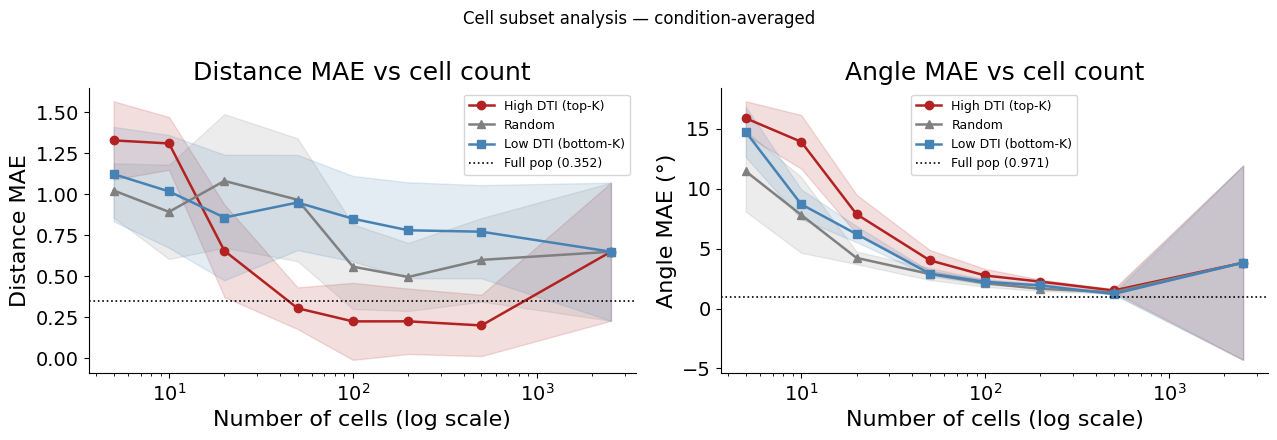

In [128]:
style_map = {
    'top_DTI':    ('firebrick',  'o', 'High DTI (top-K)'),
    'random':     ('gray',       '^', 'Random'),
    'bottom_DTI': ('steelblue',  's', 'Low DTI (bottom-K)'),
}

angle_axis = bino_res['angle_axis'].squeeze()   # fix (n_positions, 1) → (n_positions,)
distances  = bino_res['distances']

a_true = np.tile(angle_axis[None, :], (len(distances), 1))   # (n_distances, n_positions)
a_pred = bino_res['a_pred'].squeeze(-1)                       # (n_repeats, n_distances, n_positions)

d_mae_full = np.abs(bino_res['d_pred_cont'] - bino_res['d_true']).mean(axis=(1, 2))
a_mae_full = np.abs(a_pred - a_true).mean(axis=(1, 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for metric, ylabel, full_ref, ax in [
    ('d_mae', 'Distance MAE',  np.mean(d_mae_full), axes[0]),
    ('a_mae', 'Angle MAE (°)', np.mean(a_mae_full), axes[1]),
]:
    for sname, (color, marker, label) in style_map.items():
        means = [np.mean(subset_res[sname][K][metric]) for K in K_values]
        stds  = [np.std( subset_res[sname][K][metric]) for K in K_values]
        ax.plot(K_values, means, marker=marker, color=color, label=label,
                linewidth=1.8, markersize=6)
        ax.fill_between(K_values,
                        [m - s for m, s in zip(means, stds)],
                        [m + s for m, s in zip(means, stds)],
                        alpha=0.15, color=color)
    ax.axhline(full_ref, color='black', linestyle=':', linewidth=1.2,
               label=f'Full pop ({full_ref:.3f})')
    ax.set_xscale('log')
    ax.set(xlabel='Number of cells (log scale)', ylabel=ylabel)
    ax.legend(fontsize=9)

axes[0].set_title('Distance MAE vs cell count')
axes[1].set_title('Angle MAE vs cell count')
plt.suptitle('Cell subset analysis — condition-averaged', fontsize=12)
plt.tight_layout(); plt.show()


### § 1.5 — Gain structure of high-DTI cells

For the top-K DTI cells: is their gain monotone (near-preferring ↘ or far-preferring ↗)?

In [10]:
# Fit on full condition-averaged cube (all trials averaged; no split)
dec_full = FactoredMLE().fit(X_cond)
gain_all = dec_full.gain   # (n_neurons, n_distances)

N_SHOW   = 20
top_idx  = rank_dti_desc[:N_SHOW]
gain_top = gain_all[top_idx, :]   # (N_SHOW, n_distances)

# Classify monotonicity
diffs     = np.diff(gain_top, axis=1)               # (N_SHOW, n_distances - 1)
near_pref = np.all(diffs <= 0, axis=1)              # gain decreases with distance -> near-preferring
far_pref  = np.all(diffs >= 0, axis=1)              # gain increases with distance -> far-preferring
non_mono  = ~near_pref & ~far_pref
labels_   = np.where(near_pref, 'near', np.where(far_pref, 'far', 'non-mono'))
colors_   = {'near': 'steelblue', 'far': 'firebrick', 'non-mono': 'gray'}

print('Top-20 DTI cells:')
print(f'  Near-preferring (gain ↘): {near_pref.sum()}')
print(f'  Far-preferring  (gain ↗): {far_pref.sum()}')
print(f'  Non-monotone:             {non_mono.sum()}')

# Grid of gain curves
ncols = 5
nrows = N_SHOW // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 2.2))
for i, (ax, cidx) in enumerate(zip(axes.flat, top_idx)):
    t = labels_[i]
    ax.plot(distances, gain_top[i], 'o-', color=colors_[t], linewidth=2, markersize=6)
    ax.axhline(1, color='black', linewidth=0.8, linestyle=':')
    ax.set(title=f'cell {cidx}\nDTI={bino_dti[cidx]:.2f}  [{t}]',
           xlabel='distance', ylabel='gain')
plt.suptitle(f'Gain structure — top {N_SHOW} DTI cells', fontsize=12)
plt.tight_layout(); plt.show()

# Summary bar
fig, ax = plt.subplots(figsize=(4, 3))
cats_   = ['near', 'far', 'non-mono']
counts_ = [near_pref.sum(), far_pref.sum(), non_mono.sum()]
ax.bar(cats_, counts_, color=[colors_[c] for c in cats_], edgecolor='white')
ax.set(ylabel='Count', title=f'Top-{N_SHOW} DTI cells—gain monotonicity')
plt.tight_layout(); plt.show()

IndexError: index 5389 is out of bounds for axis 0 with size 2990

In [9]:
# Mean response across angles (RF profile) — same top-20 cells as gain plot above
# dec_full.mu_angle: (n_neurons, n_positions) — mean across distances
mu_top = dec_full.mu_angle[top_idx, :]   # (N_SHOW, n_positions)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 2.2))
for i, (ax, cidx) in enumerate(zip(axes.flat, top_idx)):
    t = labels_[i]
    ax.plot(deg_axis, mu_top[i], color=colors_[t], linewidth=2)
    ax.set(title=f'cell {cidx}\nDTI={bino_dti[cidx]:.2f}  [{t}]',
           xlabel='angle (°)', ylabel='mean resp (ΔF/F)')
plt.suptitle(f'Mean response across angles — top {N_SHOW} DTI cells', fontsize=12)
plt.tight_layout(); plt.show()


IndexError: index 5389 is out of bounds for axis 0 with size 2990

---
## Part 2 — Single-session, single-trial FactoredMLE

Each test observation is a **single noisy trial**, not an average.  
Templates are still built from condition-averaged *training* trials (no leakage).  
This is the realistic lower bound on performance.

### § 2.0 — Session selection & single-trial data loading

In [129]:
# Pick the session with the most reliable cells
session_counts = agg.df['session_name'].value_counts()
best_session   = session_counts.index[0]
print(f'Selected session: {best_session}  ({session_counts[best_session]} reliable cells)')
print('All sessions (reliable cell count):')
for s, c in session_counts.items():
    print(f'  {s}: {c}')

Selected session: 251126_SAM041_tiling_2_120um  (922 reliable cells)
All sessions (reliable cell count):
  251126_SAM041_tiling_2_120um: 922
  251128_SAM041_tiling_3_120um: 604
  251126_SAM041_tiling_5_120um: 566
  251126_SAM041_tiling_6_120um: 191
  251126_SAM041_tiling_1_120um: 137
  251128_SAM041_tiling_4_120um: 74
  251126_SAM041_tiling_9_120um: 18
  251128_SAM041_tiling_8_120um: 14
  251128_SAM041_tiling_7_120um: 4


In [130]:
# Raw single-trial data (no condition averaging)
X_trials, y_dist = agg.get_decoder_data(monocular=0, session=best_session)
# X_trials: (n_neurons_s, n_positions, n_trials)
# y_dist  : (n_trials,)  distance value per trial

n_neurons_s, _, n_trials_s = X_trials.shape
dist_vals_s   = np.unique(y_dist)
n_distances_s = len(dist_vals_s)

print(f'Session neurons : {n_neurons_s}')
print(f'Total trials    : {n_trials_s}')
for d in dist_vals_s:
    print(f'  distance={d}: {(y_dist == d).sum()} trials')

# DTI for this session's cells (in their aggregator order)
session_mask = agg.df['session_name'] == best_session
session_pos  = np.where(session_mask.values)[0]   # global indices into agg.df
bino_dti_s   = np.array([agg.df.iloc[i]['binocular']['DTI'] for i in session_pos])
rank_dti_s   = np.argsort(bino_dti_s)[::-1]

Session neurons : 922
Total trials    : 48
  distance=0: 12 trials
  distance=1: 12 trials
  distance=2: 12 trials
  distance=3: 12 trials


### § 2.2 — Single-trial binocular baseline + comparison to condition-averaged

In [136]:
print(bino_res.keys())

dict_keys(['d_pred_cont', 'd_pred_hard', 'a_pred', 'd_true', 'a_true', 'angle_axis', 'distances'])


In [135]:
st_bino = cross_validate_single_trial(X_trials, y_dist, dist_vals_s, deg_per_pos)

print('=== Binocular — single-trial ===')
print(f"Angle MAE:    {st_bino['angle_mae']:.2f} °")
print(f"Distance MAE: {st_bino['dist_mae_cont']:.3f}  (dist units)")
print(f"Distance acc: {st_bino['dist_acc']*100:.1f}%  (chance=25%)")

print()
print(f"{'':28s}  {'Angle MAE (°)':>14s}  {'Dist MAE':>10s}  {'Dist acc':>10s}")
cond_avg_d = np.mean(bino_res['dist_maes_cont'])
cond_avg_a = np.mean(bino_res['angle_maes'])
cond_avg_acc = np.mean(bino_res['dist_accs'])
print(f"{'Condition-averaged (multi-sess)':28s}  {cond_avg_a:>14.2f}  {cond_avg_d:>10.3f}  {cond_avg_acc*100:>9.1f}%")
print(f"{'Single-trial (this session)':28s}  {st_bino['angle_mae']:>14.2f}  {st_bino['dist_mae_cont']:>10.3f}  {st_bino['dist_acc']*100:>9.1f}%")

=== Binocular — single-trial ===
Angle MAE:    6.66 °
Distance MAE: 0.347  (dist units)
Distance acc: 66.7%  (chance=25%)

                               Angle MAE (°)    Dist MAE    Dist acc


KeyError: 'dist_maes_cont'

In [ ]:
FactoredMLE.plot_distance_results(st_bino, dist_vals_s, deg_axis,
                                   title='Binocular — single-trial')
plt.show()

FactoredMLE.plot_angle_results(st_bino, deg_axis, deg_per_pos,
                                title='Binocular — single-trial')
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for col, (res, dist_v, title_tag) in enumerate([
    (bino_res,  distances,  f'Cond-averaged\ndist MAE={np.mean(bino_res["dist_maes_cont"]):.3f}  acc={np.mean(bino_res["dist_accs"])*100:.1f}%'),
    (st_bino,   dist_vals_s, f'Single-trial\ndist MAE={st_bino["dist_mae_cont"]:.3f}  acc={st_bino["dist_acc"]*100:.1f}%'),
]):
    n_d = len(dist_v)
    # Angle scatter
    ax = axes[0, col]
    dg_t = res['a_true'] * deg_per_pos - 20
    dg_p = res['a_pred'] * deg_per_pos - 20
    mae_a = res['angle_mae'] if 'angle_mae' in res else np.mean(res['angle_maes'])
    ax.scatter(dg_t, dg_p, alpha=0.12, s=5, color='steelblue', linewidths=0)
    ax.plot([-20, 60], [-20, 60], 'r--', linewidth=1.2)
    ax.set(xlabel='True angle (°)', ylabel='Pred angle (°)',
           title=f'Angle  |  MAE={mae_a:.2f}°', aspect='equal')

    # Distance confusion
    ax = axes[1, col]
    cm   = confusion_matrix(res['d_true'], res['d_pred_hard'],
                            labels=list(range(n_d)), normalize='true')
    disp = ConfusionMatrixDisplay(cm, display_labels=[f'd={d}' for d in dist_v])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title_tag)

axes[0, 0].set_title(f'Cond-averaged  |  Angle MAE={np.mean(bino_res["angle_maes"]):.2f}°', fontsize=10)
axes[0, 1].set_title(f'Single-trial  |  Angle MAE={st_bino["angle_mae"]:.2f}°', fontsize=10)
plt.suptitle('Condition-averaged vs Single-trial — binocular', fontsize=12)
plt.tight_layout(); plt.show()

### § 2.3 — Single-trial: Binocular vs Monocular

In [ ]:
X_trials_mono, y_dist_mono = agg.get_decoder_data(monocular=1, session=best_session)
dist_vals_mono = np.unique(y_dist_mono)

st_mono = cross_validate_single_trial(X_trials_mono, y_dist_mono, dist_vals_mono, deg_per_pos)

print(f"{'':25s}  {'Angle MAE (°)':>14s}  {'Dist MAE':>10s}  {'Dist acc':>10s}")
for name, res in [('Single-trial bino', st_bino), ('Single-trial mono', st_mono)]:
    print(f"{name:25s}  {res['angle_mae']:>14.2f}  {res['dist_mae_cont']:>10.3f}  {res['dist_acc']*100:>9.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, res, dist_v) in zip(axes, [
    ('Binocular', st_bino, dist_vals_s),
    ('Monocular', st_mono, dist_vals_mono),
]):
    cm   = confusion_matrix(res['d_true'], res['d_pred_hard'],
                            labels=list(range(len(dist_v))), normalize='true')
    disp = ConfusionMatrixDisplay(cm, display_labels=[f'd={d}' for d in dist_v])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name} — single-trial\nacc={res["dist_acc"]*100:.1f}%  MAE={res["dist_mae_cont"]:.3f}')
plt.suptitle('Single-trial: Binocular vs Monocular', fontsize=12)
plt.tight_layout(); plt.show()

### § 2.4 — Single-trial DTI subset analysis + comparison to condition-averaged

Same sweep as § 1.4 but on single trials.  
The combined figure shows the performance gap across all cell-count regimes.

In [ ]:
K_values_s  = sorted(set([5, 10, 20, 50, 100, min(200, n_neurons_s), n_neurons_s]))
rng_s       = np.random.default_rng(RANDOM_STATE + 1)

rank_top_s  = rank_dti_s
rank_bot_s  = rank_dti_s[::-1].copy()

st_subset_res = {
    'top_DTI':    {K: {'d_mae': [], 'a_mae': []} for K in K_values_s},
    'random':     {K: {'d_mae': [], 'a_mae': []} for K in K_values_s},
    'bottom_DTI': {K: {'d_mae': [], 'a_mae': []} for K in K_values_s},
}

for rep in range(N_REPEATS):
    rand_s = rng_s.permutation(n_neurons_s)
    for K in K_values_s:
        K_ = min(K, n_neurons_s)
        for sname, idx_order in [
            ('top_DTI',    rank_top_s[:K_]),
            ('random',     rand_s[:K_]),
            ('bottom_DTI', rank_bot_s[:K_]),
        ]:
            res = cross_validate_single_trial(
                X_trials, y_dist, dist_vals_s, deg_per_pos, cell_idx=idx_order
            )
            st_subset_res[sname][K]['d_mae'].append(res['dist_mae_cont'])
            st_subset_res[sname][K]['a_mae'].append(res['angle_mae'])

    if (rep + 1) % 2 == 0:
        print(f'  {rep+1}/{N_REPEATS} done')

print('Done.')

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, (metric, ylabel) in enumerate([('d_mae', 'Distance MAE'), ('a_mae', 'Angle MAE (°)')]):
    for col, (results_dict, K_ax, suffix) in enumerate([
        (subset_res,    K_values,   'Cond-averaged'),
        (st_subset_res, K_values_s, 'Single-trial'),
    ]):
        ax = axes[row, col]
        for sname, (color, marker, label) in style_map.items():
            if sname not in results_dict:
                continue
            means = [np.mean(results_dict[sname][K][metric]) for K in K_ax]
            stds  = [np.std( results_dict[sname][K][metric]) for K in K_ax]
            ax.plot(K_ax, means, marker=marker, color=color, label=label,
                    linewidth=1.8, markersize=5)
            ax.fill_between(K_ax,
                            [m - s for m, s in zip(means, stds)],
                            [m + s for m, s in zip(means, stds)],
                            alpha=0.15, color=color)
        ax.set_xscale('log')
        ax.set(xlabel='Number of cells (log)', ylabel=ylabel,
               title=f'{ylabel} — {suffix}')
        ax.legend(fontsize=8)

plt.suptitle('DTI subset analysis: condition-averaged vs single-trial', fontsize=12)
plt.tight_layout(); plt.show()